# Amortized methods in geostatistics

In [1]:
import matplotlib
import matplotlib.pyplot as plt

import numpy as np

import random
from tqdm import tqdm
import time

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

/home/aloret/PycharmProjects/Neural_ST_inference/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

## Simulation

### Sampling

In [6]:
def sampling_matern(lambdaParent,lambdaDaughter,radiusCluster):

    xMin = 0
    xMax = 1
    yMin = 0
    yMax = 1

    rExt = radiusCluster  
    xMinExt = xMin - rExt
    xMaxExt = xMax + rExt
    yMinExt = yMin - rExt
    yMaxExt = yMax + rExt

    xDeltaExt = xMaxExt - xMinExt
    yDeltaExt = yMaxExt - yMinExt
    areaTotalExt = xDeltaExt * yDeltaExt  

    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent)  
    
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent)
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent)

    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent) 
    numbPoints = sum(numbPointsDaughter)

    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints) 
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints)) 
    xx0 = rho * np.cos(theta)
    yy0 = rho * np.sin(theta)

    xx = np.repeat(xxParent, numbPointsDaughter)
    yy = np.repeat(yyParent, numbPointsDaughter)

    xx = xx + xx0
    yy = yy + yy0

    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax))
    xx = xx[booleInside]
    yy = yy[booleInside]

    # data = {'x1': xx, 'x2': yy}
    # sample = pd.DataFrame(data)

    sample = gl.Db()
    sample.addColumns(xx,"x1")
    sample.addColumns(yy,"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample


def grid():

    sample = gl.Db()
    sample.addColumns(np.repeat(np.linspace(0,1,100),100),"x1")
    sample.addColumns(np.tile(np.linspace(0,1,100),100),"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample 

theta_size = 2

In [7]:
def simulation_matern(sample, theta_range, theta_std, plot=False):

    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range*np.sqrt(8), param = 1, sill = theta_std**2)  # range is the practical range of Matérn with smoothness parameter = 1
    err = gl.simtub(None, sample, model, None, nbsimu=1, seed=0, nbtuba = 1000)

    if plot:
            fig, axs = plt.subplots(1, 1, figsize=(7, 7), constrained_layout=True)

            axs.scatter(sample['x1'], sample['x2'], c=sample['Simu'], s=8) 
        
            axs.set_xlabel('x1')
            axs.set_ylabel('x2')
            axs.set_title('Simu Values with Selected Points')

            axs.set_xlim([0, 1])
            axs.set_ylim([0, 1])
            axs.axis('equal')

            plt.show()

    return sample

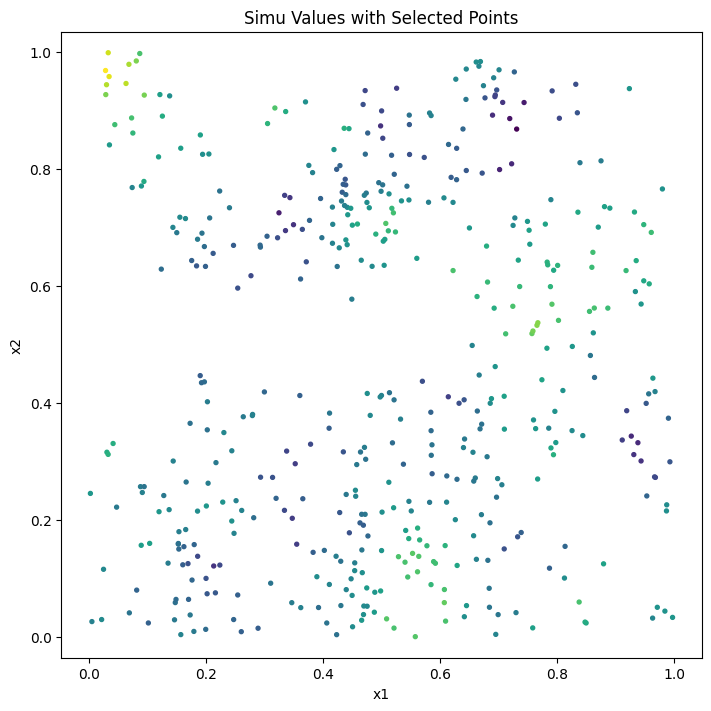


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 473

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = Simu - Locator = z1

In [8]:
sample = sampling_matern(60,500//60,.1)
theta_range, theta_std = .1, 1.
simulation_matern(sample, theta_range, theta_std, plot=True)

In [9]:
def points_to_grid(sample, nb_bins=100):
    
    bin_size = 1.0 / nb_bins

    x1 = torch.tensor(sample['x1'], dtype=torch.float32)
    x2 = torch.tensor(sample['x2'], dtype=torch.float32)
    values = torch.tensor(sample['Simu'], dtype=torch.float32)
    
    ix = torch.clamp((x1 / bin_size).long(), max=nb_bins - 1)
    iy = torch.clamp((x2 / bin_size).long(), max=nb_bins - 1)

    flat_idx = ix * nb_bins + iy
    
    # value_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
    # count_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
        
    # value_flat.index_add_(0, flat_idx, values)
    # count_flat.index_add_(0, flat_idx, torch.ones_like(values))

    # mean_grid = torch.empty_like(value_flat)
    # mean_grid[:] = float('nan')
    # mask = count_flat > 0
    # mean_grid[mask] = value_flat[mask] / count_flat[mask]

    # return mean_grid.view(nb_bins, nb_bins)

    value_flat = torch.full((nb_bins * nb_bins,), float('nan'))

    unique_idx = flat_idx.unique()
    for idx in unique_idx:
        indices_in_cell = torch.where(flat_idx == idx)[0]
        chosen = indices_in_cell[torch.randint(0, len(indices_in_cell), (1,))]
        value_flat[idx] = values[chosen]

    return value_flat.view(nb_bins, nb_bins)

In [20]:
def datamaker(constant_product, n, m, as_grid=False, bins=100, range_min=.05, range_max=.5,std_min=.1, std_max=1.,lambdaParent_min=10,lambdaParent_max=60,radiusCluster = 0.15,log=False):

    datalist=[]

    range_list = np.random.uniform(range_min,range_max,m)
    std_list = np.random.uniform(std_min, std_max,m)
    lambdaParent = np.random.uniform(lambdaParent_min, lambdaParent_max,(n,m))
    lambdaDaughter = constant_product / lambdaParent

    print("i : ", end='')

    for i in range(n):

        print(i, end='|')

        pi = torch.randperm(m)

        for j in range(m):

            if as_grid :
                sample = grid() 
            else :
                sample = sampling_matern(lambdaParent[i,j],lambdaDaughter[i,j],radiusCluster)
            simu = simulation_matern(sample, range_list[j], std_list[j])
            simu = points_to_grid(simu, bins)
    
            theta = torch.tensor((range_list[j], std_list[j]))
            theta_perm = torch.tensor((range_list[pi[j]], std_list[pi[j]]))
    
            datalist.append((simu,theta,torch.tensor([1])))
            datalist.append((simu,theta_perm,torch.tensor(0)))

    return datalist #GridSetDataset(datalist)datalist)

In [83]:
n_points = 500

n_train = 15
m_train = 15

n_test = 5
m_test = 2

batch_size = 5 

In [84]:
data_train = datamaker(n_points, n_train, m_train, as_grid=True)

i : 0|1|2|3|4|5|6|7|8|9|10|11|12|13|14|

In [23]:
data_test = datamaker(n_points, n_test, m_test, as_grid=True)

i : 0|1|2|3|4|

tensor([0.3191, 0.9507], dtype=torch.float64) tensor([1])


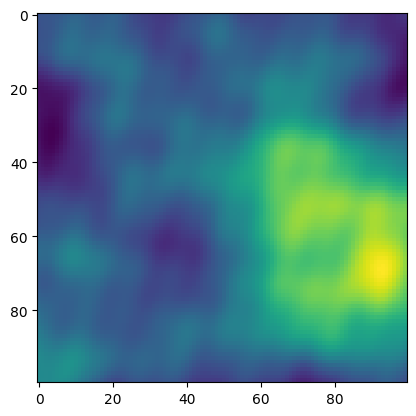

In [82]:
k = 8
plt.imshow(data_train[k][0])
print(data_train[k][1], data_train[k][2])

In [85]:
class GridSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
                
        data = self.datalist[idx][0]
        mask = (~torch.isnan(data)).float()
        
        data = torch.nan_to_num(data, nan=0.)
        
        # data = torch.stack([data, mask], dim=0) 
        data = data.unsqueeze(0)
        
        theta = self.datalist[idx][1]

        label = torch.tensor([self.datalist[idx][2]])
        
        return data, theta, label

dataset_train = GridSetDataset(data_train)
dataset_test = GridSetDataset(data_test)

loader_train = DataLoader(dataset_train, batch_size, shuffle=True)

## CNN

In [86]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 10, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 5, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)  # ~vec(·) 
        self.dense = nn.Sequential(
            nn.Linear(hidden+2, 32),
            nn.ReLU(),
            nn.Linear(32, out_dim),  
            # nn.Softmax(dim=1) 
        )


    def forward(self, x, theta):

        x = x.float()
        theta = theta.float()
        
        h = self.conv(x)
        h = self.pool(h).view(h.shape[0], -1)
        h = torch.cat((h, theta),dim=1)
        
        out = self.dense(h)
        
        return out

In [87]:
def train_cnn(model, optimizer, loader):
    
    model.train()
    CE = nn.CrossEntropyLoss() # torch.nn.BCELoss(reduction="mean") 
    
    sum_loss = []

    for i, (x, theta, classi) in enumerate(loader):
        optimizer.zero_grad()

        x, theta, label = x.to(device), theta.to(device), classi.to(device).flatten()

        # print(x.shape, theta, classi)

        output = model(x, theta)
        
        batch_loss = CE(output, label)
        
        batch_loss.backward()
        optimizer.step()
        
        # sum_loss += torch.mean(torch.abs(output - theta),dim=0)
        sum_loss.append(batch_loss.item())

    return sum_loss #/ len(loader)



In [88]:
model_grid = CNN_network(in_channels=1).to(device)

optimizer_grid = torch.optim.Adam(model_grid.parameters(), lr=1e-3)

Epoch 50/50: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [02:07<00:00,  2.55s/it, loss=0.40239345928033193]

Time to train : 127.59s


Text(0, 0.5, 'Cross Entropy')

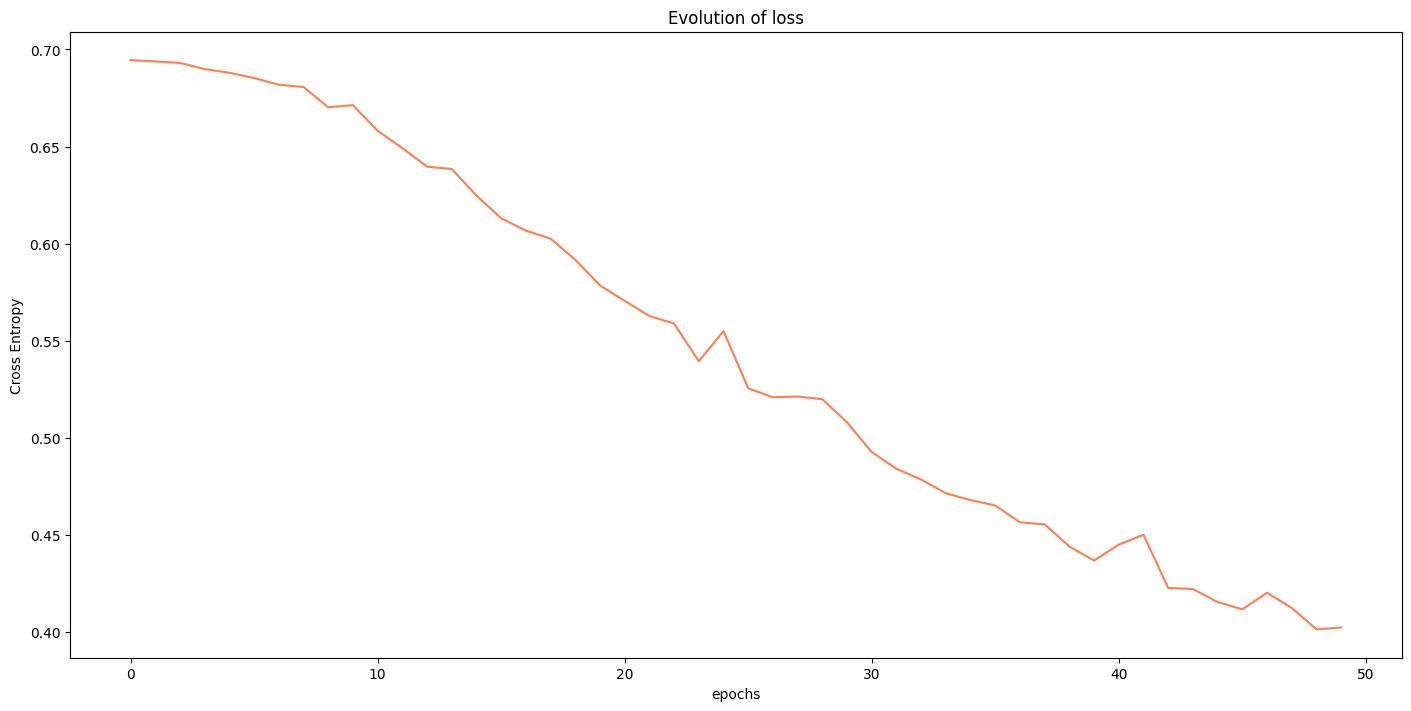

In [89]:
n_epochs = 50
all_loss_train_grid=np.zeros((n_epochs,))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_grid = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid,
        optimizer_grid,
        loader_train,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{np.mean(loss)}")
    all_loss_train_grid[epoch] = np.mean(loss)

time_train_grid = time.time() - time_train_grid

print(f"Time to train : {time_train_grid:.2f}s")

fig_cnn, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_grid, 'coral')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

### Likelihood

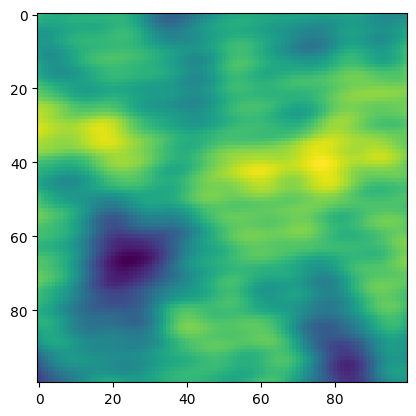

In [133]:
true_range = .3
true_std = .4

simu = simulation_matern(grid(), true_range, true_std)
simu = points_to_grid(simu, 100)

plt.imshow(simu)

In [134]:
def estimate_likelihood_surface(model, simu, theta_grid):
    
    model.eval()
    
    L_values = []
    simu = simu.to(device)
    
    with torch.no_grad():
        for theta in theta_grid:
            
            theta_t = torch.tensor(theta, dtype=torch.float32).unsqueeze(0).to(device)
            
            h = model(simu, theta_t)
            p = torch.softmax(h, dim=1)[:, 1] 
            
            L = p / (1 - p)
            L_values.append(L.item())
            
    return torch.tensor(L_values)

In [135]:
range_min, range_max = 0.05, 0.5
std_min, std_max = 0.1, 1.0

n_range = 20
n_std = 20

range_vals = torch.linspace(range_min, range_max, n_range)
std_vals = torch.linspace(std_min, std_max, n_std)

R, S = torch.meshgrid(range_vals, std_vals, indexing='ij')
theta_grid = torch.stack([R.flatten(), S.flatten()], dim=1)

/tmp/ipykernel_13665/3967714795.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta_t = torch.tensor(theta, dtype=torch.float32).unsqueeze(0).to(device)


tensor([0.5000, 0.5737])

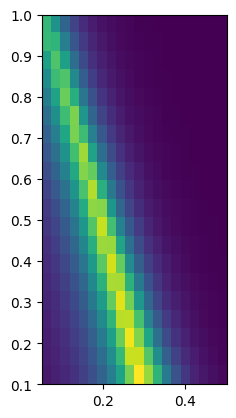

In [145]:
L_values = estimate_likelihood_surface(model_grid, simu.unsqueeze(0).unsqueeze(0), theta_grid)

plt.imshow(L_values.reshape(n_range,n_std),extent=[range_min, range_max,std_min, std_max], aspect='equal')

theta_grid[torch.argmax(L_values)]

In [138]:
loader_grid_test = DataLoader(
    dataset_test, 
    1, 
    shuffle=False
)

all_loss_test_grid = np.zeros(n_test*m_test*2)

time_test_grid = time.time()

MAE = torch.nn.L1Loss(reduction="mean")

for i, (data_test, theta_test, label_test) in enumerate(loader_grid_test) : 

    L_values = estimate_likelihood_surface(model_grid, data_test, theta_grid)
    
    output = theta_grid[torch.argmax(L_values)]

    all_loss_test_grid[i] = MAE(output, theta_test)

    # print(f"| RANGE {output[0,0]:.4f} - {theta_test[0,0]:.4f} = {abs(output[0,0]-theta_test[0,0]):.4f} | STD {output[0,1]:.4f} - {theta_test[0,1]:.4f} = {abs(output[0,1]-theta_test[0,1]):.4f} |")

time_test_grid = time.time() - time_test_grid

print(f"\nTime to test : {time_test_grid:.2f}s")

print("Test loss :", np.mean(all_loss_test_grid), "±", np.std(all_loss_test_grid))

/tmp/ipykernel_13665/3967714795.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta_t = torch.tensor(theta, dtype=torch.float32).unsqueeze(0).to(device)



Time to test : 12.70s
Test loss : 0.08996252703465488 ± 0.033428796642041986


## Maximum likelyhood

In [37]:
def matern_covariance_from_coords(coords, range_theta, std_theta):
    db = gl.Db()
    db.addColumns(coords[:,0],"x1")
    db.addColumns(coords[:,1],"x2")
    db.setLocators(["x1","x2"],gl.ELoc.X)

    model = gl.Model.createFromParam(
        type=gl.ECov.MATERN,
        range=range_theta* np.sqrt(8),
        sill=std_theta**2,
        param=1.
    )

    cov = gl.evalCovMatSym(model,db)

    vals = cov.getValues()
    cov_np = np.array(vals).reshape(cov.getNRows(), cov.getNCols())

    return cov_np

In [38]:
def nll(theta, coords, values, eps=1e-6): 
    # https://soft.mines-paristech.fr/gstlearn/demos-latest/python/Tuto_LogLikelihood.html

    range_theta, std_theta = theta
    cov = matern_covariance_from_coords(coords, range_theta, std_theta)
    cov += eps * np.eye(cov.shape[0])

    L = linalg.cholesky(cov) 

    # solve Σ^{-1} @ values 
    alpha = linalg.cho_solve((L, False), values) 

    # Compute values.T @ Σ^{-1} @ values 
    quad = float(np.dot(values,alpha))

    # det term, https://math.stackexchange.com/questions/3158303/using-cholesky-decomposition-to-compute-covariance-matrix-determinant
    logdet = 2.0 * np.sum(np.log(np.diag(L)))

    return 0.5 * (logdet + quad + values.size * np.log(2.0 * np.pi))

In [39]:
def mle_matern(coords, values, theta0=(.2, .5)):

    def obj(theta):
        return nll(theta, coords, values)

    res = minimize(obj, theta0, method="Nelder-Mead", options={"maxiter":2000})
    return res.x, res

In [40]:
all_loss_test_ML = np.zeros((len(sampling_test),theta_size))

time_test_ML = time.time()

for i, (data_test, theta_test) in enumerate(sampling_test) : 

    output, _ = mle_matern(data_test[["x1","x2"]],data_test["Simu"])

    all_loss_test_ML[i] = np.abs(output - np.array(theta_test))

    print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML

print(f"\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

| RANGE 1.1110 - 0.4873 = 0.6237 | STD 0.9017 - 0.7334 = 0.1683 |
| RANGE 0.1727 - 0.2153 = 0.0426 | STD 0.1295 - 0.1472 = 0.0177 |
| RANGE 0.2069 - 0.2001 = 0.0068 | STD 1.0009 - 0.9981 = 0.0028 |
| RANGE 0.4022 - 0.4247 = 0.0226 | STD 0.6276 - 0.6401 = 0.0125 |
| RANGE 0.3604 - 0.3672 = 0.0068 | STD 0.4696 - 0.5051 = 0.0356 |
| RANGE 0.2292 - 0.3950 = 0.1658 | STD 0.1926 - 0.2673 = 0.0748 |
| RANGE 0.2583 - 0.3165 = 0.0582 | STD 0.5638 - 0.8144 = 0.2506 |
| RANGE 0.3999 - 0.3448 = 0.0551 | STD 0.6944 - 0.6372 = 0.0572 |
| RANGE 0.3954 - 0.2044 = 0.1910 | STD 0.4652 - 0.3435 = 0.1217 |
| RANGE 0.2189 - 0.2389 = 0.0200 | STD 0.3034 - 0.2837 = 0.0197 |

Time to test : 42.70s
Test loss : [0.11925538 0.07609795] ± [0.1788789  0.07684246]


## Conclusion

/tmp/ipykernel_2025642/3301954724.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_2025642/3301954724.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


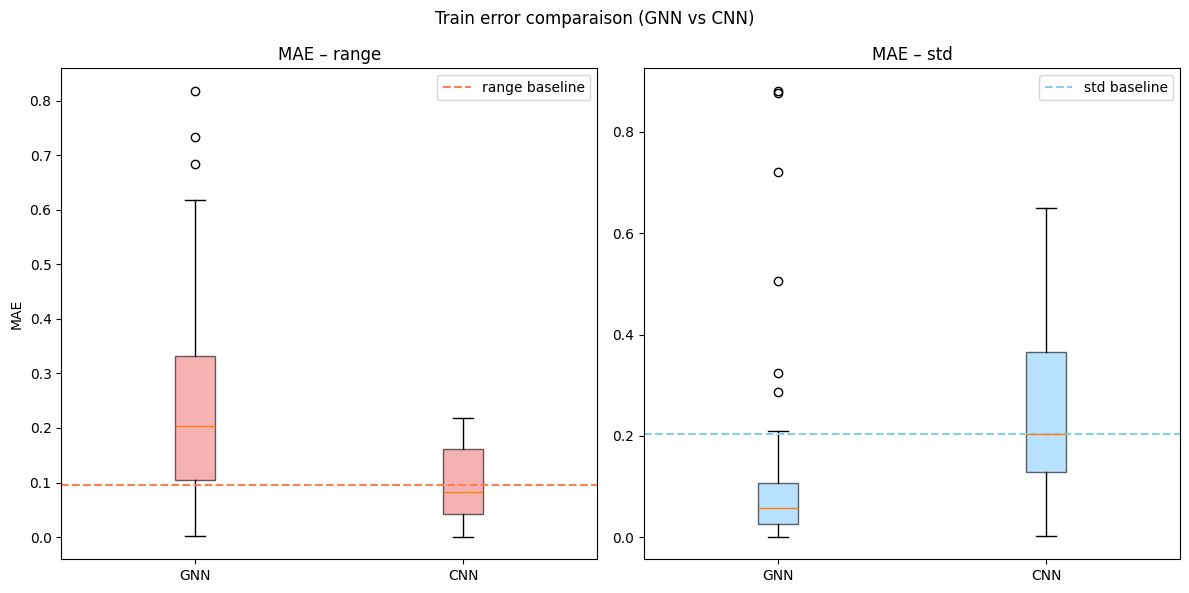

In [41]:
methods = ['GNN', 'CNN']

loss_range = [
    all_loss_train_graph[-1, :, 0],
    all_loss_train_grid[-1, :, 0],
]

loss_std = [
    all_loss_train_graph[-1, :, 1],
    all_loss_train_grid[-1, :, 1],
]

### Boxplot
fig_box_train, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Train error comparaison (GNN vs CNN)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2025642/1451531685.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_2025642/1451531685.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


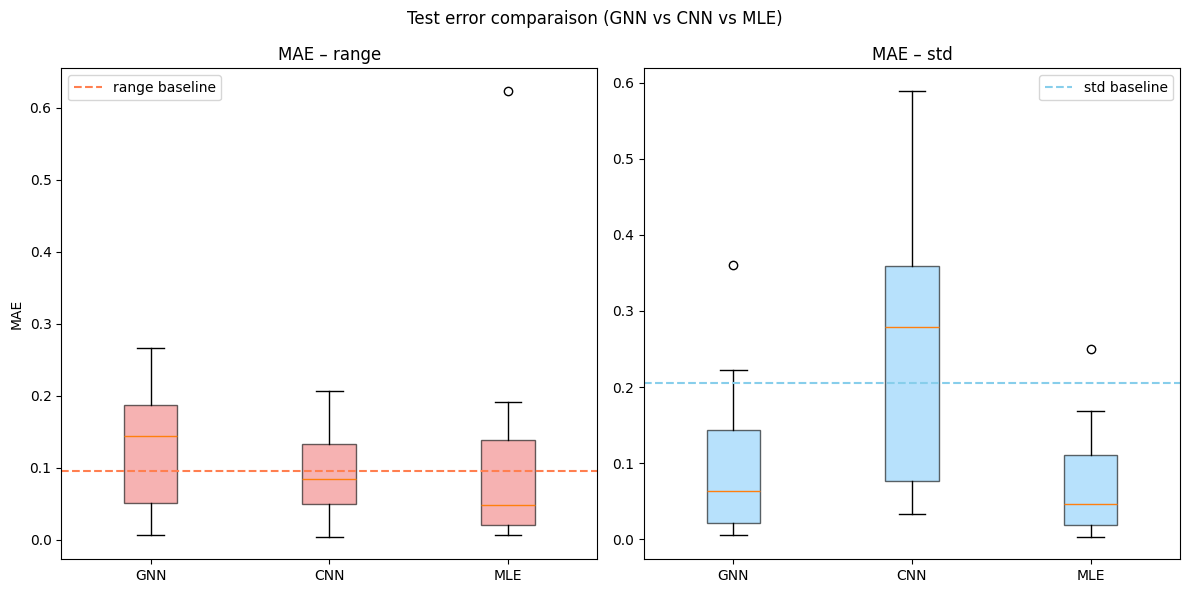

In [42]:
methods = ['GNN', 'CNN', 'MLE']

loss_range = [
    all_loss_test_graph[:, 0],
    all_loss_test_grid[:, 0],
    all_loss_test_ML[:, 0],
]

loss_std = [
    all_loss_test_graph[:, 1],
    all_loss_test_grid[:, 1],
    all_loss_test_ML[:, 1],
]

### Boxplot
fig_box_test, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Test error comparaison (GNN vs CNN vs MLE)")
plt.tight_layout()
plt.show()

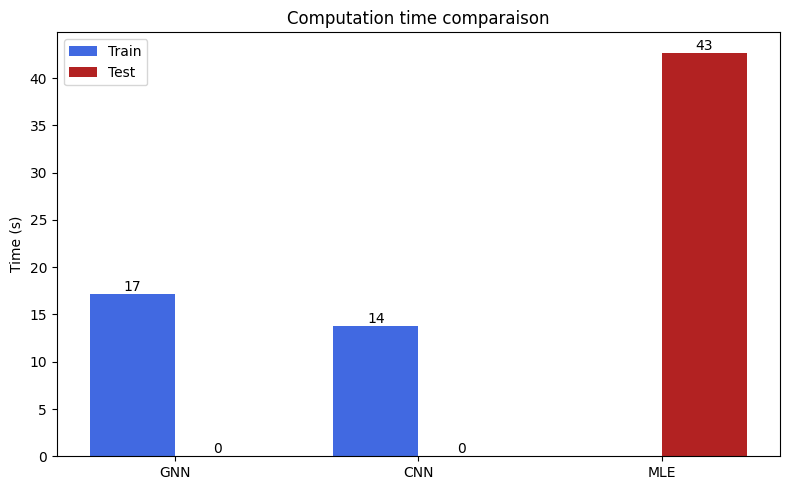

<Figure size 640x480 with 0 Axes>

In [43]:
### Time
train_times = [time_train_graph, time_train_grid, np.nan]  
test_times = [time_test_graph, time_test_grid, time_test_ML]

x = np.arange(len(methods))
width = 0.35

fig_time, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

plt.savefig("myImagePDF.pdf", format="pdf", bbox_inches="tight")

In [44]:
import json
import os

all_loss_train = {"GNN":all_loss_train_graph.tolist(),"CNN":all_loss_train_grid.tolist()}
all_loss_test = {"GNN":all_loss_test_graph.tolist(),"CNN":all_loss_test_grid.tolist(),"MLE":all_loss_test_ML.tolist()}
path = f"results/{time_train_graph+time_train_grid+time_test_ML:.0f}time-{n_train}ntrain-{n_test}ntest-{n_points}npoints"

os.mkdir(path)
with open(path+"/all_loss", 'w') as f:
    json.dump({'train':all_loss_train, 'test':all_loss_test}, f)

In [45]:
# fig_box_train.savefig(path+"/score_train.pdf", format="pdf", bbox_inches="tight")
fig_box_train.savefig(path+"/score_train.png", format="png", bbox_inches="tight")
# fig_box_test.savefig(path+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(path+"/score_test.png", format="png", bbox_inches="tight")
# fig_time.savefig(path+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(path+"/time.png", format="png", bbox_inches="tight")

# fig_gnn.savefig(path+"/gnn.pdf", format="pdf", bbox_inches="tight")
fig_gnn.savefig(path+"/gnn_train_evolution.png", format="png", bbox_inches="tight")
# fig_cnn.savefig(path+"/cnn.pdf", format="pdf", bbox_inches="tight")
fig_cnn.savefig(path+"/cnn_train_evolution.png", format="png", bbox_inches="tight")
